# 10. 의사결정나무 Study 데이터 실습 (Decision Tree Study)

실제 학습자 데이터(`Study.공유.csv`)에서 타깃(`survived`) 결측 행을 제거하고, `stratify=y` 분할 후 훈련 세트(`X_tr`)의 평균으로만 수치형 피처 결측치를 대체(데이터 누수 방지)한 뒤 `DecisionTreeClassifier(max_depth=4, min_samples_leaf=2)`로 분류 성능과 피처 중요도를 분석합니다.

원본 노트북 Lv2_Python_1119_DecisionTree_Study.ipynb

In [21]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix

In [22]:
from pathlib import Path
import pandas as pd

data_dir = DATA_DIR if 'DATA_DIR' in globals() else Path('data')
if not (data_dir / 'Study.공유.csv').is_file():
    data_dir = Path('Study_Python') / '[7] Machine_Learning' / 'data'
if not (data_dir / 'Study.공유.csv').is_file():
    data_dir = Path('..') / 'Study_Python' / '[7] Machine_Learning' / 'data'
data = pd.read_csv(data_dir / 'Study.공유.csv')

In [23]:
# ====== 데이터 확인 ======
data.head()

,ID,survived,Month,AGE,StudyCnt_M1,StudyCntCnt_M2,StudyCntCnt_M3,StudyIndex_M1,StudyIndex_M2,StudyIndex_M3,Exam1_M1,Exam1_M2,Exam1_M3,Exam2_M1,Exam2_M2,Exam2_M3,Exam3_M1,Exam3_M2,Exam3_M3
0,1,1,39,52,19.0,14.0,20.0,45.0,41.0,57.0,92.76,96.43,93.75,84.96,85.25,92.28,67.42,76.65,95.88
1,2,1,5,49,31.0,22.0,27.0,72.0,73.0,81.0,96.65,95.45,95.56,105.90,109.56,111.27,102.57,94.68,105.88
2,3,1,1,19,2.0,NaN,NaN,41.0,NaN,NaN,100.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,1,8,17,31.0,7.0,NaN,88.0,63.0,NaN,92.14,100.00,NaN,112.28,105.98,NaN,119.20,NaN,NaN
4,5,1,7,17,42.0,47.0,41.0,32.0,33.0,33.0,62.78,71.20,71.90,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
############### 중요 ################
### 클래스 비율 확인
### survived

data['survived'].value_counts()

,count
survived,
1,29796
0,868


In [25]:
### 기타 EDA

print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30664 entries, 0 to 30663
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ID              30664 non-null  int64  
 1   survived        30664 non-null  int64  
 2   Month           30664 non-null  int64  
 3   AGE             30664 non-null  int64  
 4   StudyCnt_M1     30657 non-null  float64
 5   StudyCntCnt_M2  27932 non-null  float64
 6   StudyCntCnt_M3  26123 non-null  float64
 7   StudyIndex_M1   30657 non-null  float64
 8   StudyIndex_M2   27932 non-null  float64
 9   StudyIndex_M3   26123 non-null  float64
 10  Exam1_M1        25731 non-null  float64
 11  Exam1_M2        23522 non-null  float64
 12  Exam1_M3        22160 non-null  float64
 13  Exam2_M1        27406 non-null  float64
 14  Exam2_M2        25188 non-null  float64
 15  Exam2_M3        23707 non-null  float64
 16  Exam3_M1        24640 non-null  float64
 17  Exam3_M2        22692 non-null 

In [34]:
# ====== 피처/타깃 설정  ======
target_col = "survived"          # 타켓
id_like = ["ID"]                 # id.. 설명 변수에서 제외 하기 위해..

# feature_cols = [c for c in data.columns if c not in id_like + [target_col]]
feature_cols = []
exclude_cols = id_like + [target_col]

for c in data.columns:
    if c not in exclude_cols:
        feature_cols.append(c)



In [35]:
feature_cols

['Month',
 'AGE',
 'StudyCnt_M1',
 'StudyCntCnt_M2',
 'StudyCntCnt_M3',
 'StudyIndex_M1',
 'StudyIndex_M2',
 'StudyIndex_M3',
 'Exam1_M1',
 'Exam1_M2',
 'Exam1_M3',
 'Exam2_M1',
 'Exam2_M2',
 'Exam2_M3',
 'Exam3_M1',
 'Exam3_M2',
 'Exam3_M3']

In [ ]:
# NaN 값을 포함하는 survived 열의 행을 제거합니다.
data.dropna(subset=[target_col], inplace=True)

X = data[feature_cols].copy()
y = data[target_col].astype(int)

In [27]:
# 결측치 확인 (데이터 누수 방지를 위해 train_test_split 이후 훈련 세트 평균으로 대체)
print(X.isnull().sum()[X.isnull().sum() > 0])

In [28]:
# ====== 데이터 분할 및 누수 방지 결측 대체 ======
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
train_means = X_tr.mean(numeric_only=True)
X_tr = X_tr.fillna(train_means)
X_te = X_te.fillna(train_means)

In [29]:
# ====== DT 모델 ======
dt = DecisionTreeClassifier(
    max_depth=4,              # 과적합 방지(필요 시 조정)
    min_samples_leaf=2,       # 너무 작은 잎 노드 방지
    random_state=42
)
dt.fit(X_tr, y_tr)

DecisionTreeClassifier(max_depth=4, min_samples_leaf=2, random_state=42)

In [30]:
# ====== 평가 ======
y_pred = dt.predict(X_te)
print("\n[Classification Report]")
print(classification_report(y_te, y_pred, digits=4))

print("[Confusion Matrix]")
print(confusion_matrix(y_te, y_pred))


[Classification Report]
              precision    recall  f1-score   support

           0     0.1429    0.0057    0.0110       174
           1     0.9718    0.9990    0.9852      5959

    accuracy                         0.9708      6133
   macro avg     0.5573    0.5024    0.4981      6133
weighted avg     0.9482    0.9708    0.9576      6133

[Confusion Matrix]
[[   1  173]
 [   6 5953]]


In [31]:
# ====== 피처 중요도 ======
imp = pd.Series(dt.feature_importances_, index=feature_cols).sort_values(ascending=False)
print("\n[Feature Importances]")
print(imp)



[Feature Importances]
StudyCnt_M1       0.371462
AGE               0.254627
StudyCntCnt_M3    0.149472
Month             0.071188
StudyIndex_M1     0.061777
Exam2_M2          0.046917
Exam3_M1          0.022931
StudyIndex_M2     0.021626
StudyCntCnt_M2    0.000000
Exam1_M1          0.000000
StudyIndex_M3     0.000000
Exam1_M3          0.000000
Exam1_M2          0.000000
Exam2_M1          0.000000
Exam2_M3          0.000000
Exam3_M2          0.000000
Exam3_M3          0.000000
dtype: float64


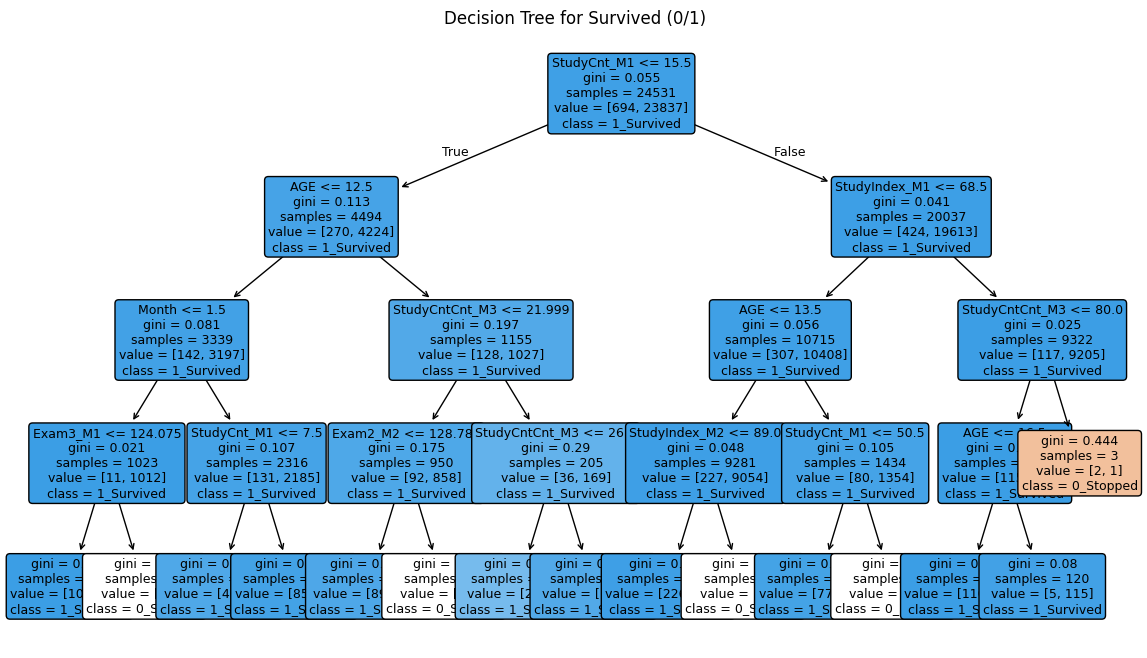

In [32]:
# ====== 트리 시각화 ======
plt.figure(figsize=(14, 8))
plot_tree(
    dt,
    feature_names=feature_cols,
    class_names=["0_Stopped", "1_Survived"],
    filled=True, rounded=True, fontsize=9
)
plt.title("Decision Tree for Survived (0/1)")
plt.show()